# DockingCopilot Skill 可复现演示

本 notebook 从头顺序执行一次完整的分子对接闭环（真实运行，非模拟）。

**科学前提**：AutoDock Vina 的 affinity 是经验打分函数与构象搜索的结果，
不等于实验结合自由能、Kd、Ki、IC50 或任何药效结论。

## 1. 环境和版本

In [1]:
import json
import platform
import sys

import Bio
import meeko
import rdkit

print("python   ", sys.version.split()[0])
print("rdkit    ", rdkit.__version__)
print("meeko    ", meeko.__version__)
print("biopython", Bio.__version__)
try:
    from vina import Vina

    print("vina     ", Vina.version)
except Exception as exc:  # noqa: BLE001
    print("vina python api unavailable:", exc)
print("platform ", platform.platform(), platform.machine())

python    3.11.15
rdkit     2025.09.5
meeko     0.7.1
biopython 1.87
vina python api unavailable: type object 'Vina' has no attribute 'version'
platform  macOS-26.5.2-arm64-arm-64bit arm64


## 2. 加载仓库示例输入（相对路径）

In [2]:
from pathlib import Path

# notebook 位于 notebooks/，项目根为其上一级；不使用任何绝对路径
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "backend"))

input_path = PROJECT_ROOT / "examples" / "inputs" / "multiple_ligands.json"
payload = json.loads(input_path.read_text(encoding="utf-8"))
print("job_name:", payload["job_name"])
print(json.dumps(payload["ligands"], indent=2))

job_name: multiple_ligands_demo
[
  {
    "ligand_id": "methane",
    "smiles": "C",
    "name": "methane"
  },
  {
    "ligand_id": "benzene",
    "smiles": "c1ccccc1",
    "name": "benzene"
  },
  {
    "ligand_id": "acetic_acid",
    "smiles": "CC(=O)O",
    "name": "acetic acid"
  }
]


## 3. 校验输入（Pydantic + jsonschema 双重校验）

In [3]:
import jsonschema

from app.schemas import DockingInput

docking_input = DockingInput.model_validate(payload)
schema = json.loads(
    (PROJECT_ROOT / "schemas" / "docking_input.schema.json").read_text(encoding="utf-8")
)
jsonschema.validate(instance=payload, schema=schema)
print(
    "Pydantic OK, jsonschema OK;",
    f"{len(docking_input.ligands)} ligands,",
    f"seed={docking_input.docking_parameters.seed}",
)

Pydantic OK, jsonschema OK; 3 ligands, seed=42


## 4. 准备 ligand（SMILES → 3D 构象 → 描述符 → PDBQT）

构象经 ETKDGv3（seed=42）生成、MMFF94 优化（不可用时受控回退 UFF 并记录警告），
PDBQT 经 Meeko 写出。

ligand_id: methane | status: SUCCESS
force field: MMFF94
conformer energy: 0.026 kcal/mol (力场能量，不是结合能)
preparation warnings: []


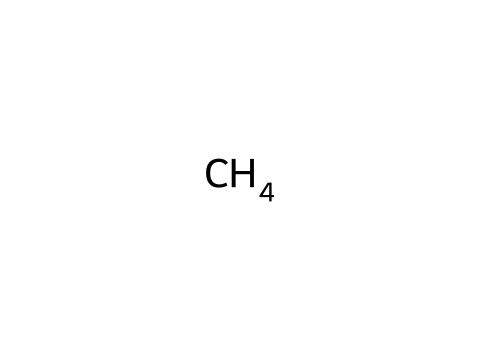

In [4]:
import tempfile

from IPython.display import SVG, display

from app.services import ligand_service

with tempfile.TemporaryDirectory() as tmp:
    tmp_dir = Path(tmp)
    demo_result = ligand_service.prepare_ligand(
        docking_input.ligands[0], docking_input.ligand_preparation, tmp_dir
    )
    meta = json.loads((tmp_dir / "ligand_metadata.json").read_text(encoding="utf-8"))
    print("ligand_id:", demo_result.ligand_id, "| status:", demo_result.status)
    print("force field:", meta["force_field_used"])
    print(
        "conformer energy:", round(meta["conformer_energy"], 3),
        "kcal/mol (力场能量，不是结合能)",
    )
    print("preparation warnings:", meta["preparation_warnings"])
    display(SVG((tmp_dir / "ligand_2d.svg").read_bytes()))

## 5. 分析 receptor（链/原子/异源实体/包围盒）

In [5]:
from app import config
from app.services import receptor_service
from app.utils.files import safe_resolve

receptor_path = safe_resolve(docking_input.receptor.source, config.PROJECT_ROOT)
report = receptor_service.analyze_receptor(receptor_path)
print("receptor:", docking_input.receptor.source)
print("chains:", report["chains"])
print("atom_count:", report["atom_count"], "| residues:", report["residue_count"])
print("hetero entities:", len(report["hetero_entities"]))
bbox_min, bbox_max = receptor_service.bounding_box_from_report(report)
print("bounding box min:", [round(x, 2) for x in bbox_min], "Å")
print("bounding box max:", [round(x, 2) for x in bbox_max], "Å")

receptor: examples/data/sample_receptor.pdb
chains: ['A']
atom_count: 1975 | residues: 257
hetero entities: 0
bounding box min: [-11.24, -15.87, -4.44] Å
bounding box max: [41.37, 24.88, 49.85] Å


## 6. 显示 docking box（四模式之一：explicit）

In [6]:
from app.services import box_service

box_report = dict(report)
box_report["bounding_box"] = (bbox_min, bbox_max)
box_result = box_service.build_box(docking_input.docking_box, box_report)
print("mode:  ", box_result.mode)
print("center:", box_result.center, "Å")
print("size:  ", box_result.size, "Å")
print("volume:", box_result.volume_angstrom3, "Å³")
print("warnings:", box_result.warnings)

mode:   explicit
center: [18.3, 2.3, 21.4] Å
size:   [20.0, 20.0, 20.0] Å
volume: 8000.0 Å³
warnings: []


## 7. 运行 Vina（真实对接，固定 seed=42）

调用完整工作流 `run_job`：validate → ligand → receptor → box → vina →
parse → metrics → interpret → manifest → package。

In [7]:
from app.workflow.runner import run_job

outcome = run_job(docking_input)
print("job_id:", outcome.job_id)
print("state: ", outcome.state.value)
assert outcome.state.value == "SUCCESS", outcome.structured_error
job_dir = outcome.job_dir
for res in outcome.output.results:
    print(
        f"{res.ligand_id}: status={res.status} "
        f"best={res.best_affinity_kcal_mol} kcal/mol "
        f"poses={len(res.poses)}"
    )

2026-08-05 11:59:06,530 [INFO] dockskill.workflow: job 20260805-035906_multiple_ligands_demo created in outputs/20260805-035906_multiple_ligands_demo


2026-08-05 11:59:06,532 [INFO] dockskill.workflow: input schema valid; 3 ligand(s)


2026-08-05 11:59:06,540 [INFO] dockskill.workflow: ligand methane prepared


2026-08-05 11:59:06,558 [INFO] dockskill.workflow: ligand benzene prepared


2026-08-05 11:59:06,568 [INFO] dockskill.workflow: ligand acetic_acid prepared


2026-08-05 11:59:06,580 [INFO] dockskill.workflow: receptor analyzed: chains=['A'] atoms=1975


... (3 outputs left out)

2026-08-05 11:59:17,484 [INFO] dockskill.workflow: ligand acetic_acid docked: best=-3.542 kcal/mol, 9 pose(s)


2026-08-05 11:59:17,497 [INFO] dockskill.workflow: manifest.json written (15 artifacts hashed)


2026-08-05 11:59:17,501 [INFO] dockskill.workflow: job 20260805-035906_multiple_ligands_demo finished: success: 3/3 ligand(s) docked


job_id: 20260805-035906_multiple_ligands_demo
state:  SUCCESS
methane: status=SUCCESS best=-0.896 kcal/mol poses=9
benzene: status=SUCCESS best=-4.526 kcal/mol poses=9
acetic_acid: status=SUCCESS best=-3.542 kcal/mol poses=9


## 8. 解析 top poses

In [8]:
print(f"{'ligand':<14}{'rank':>5}{'affinity':>12}{'rmsd_lb':>9}{'rmsd_ub':>9}")
for res in outcome.output.results:
    for pose in res.poses[:3]:  # 只展示 top-3，避免输出过大
        print(
            f"{res.ligand_id:<14}{pose.rank:>5}"
            f"{pose.affinity_kcal_mol:>12.3f}{pose.rmsd_lb:>9.3f}{pose.rmsd_ub:>9.3f}"
        )

ligand         rank    affinity  rmsd_lb  rmsd_ub
methane           1      -0.896    0.000    0.000
methane           2      -0.883   17.780   17.780
methane           3      -0.869   19.948   19.948
benzene           1      -4.526    0.000    0.000
benzene           2      -4.447    0.319    2.772
benzene           3      -4.412    0.470    2.023
acetic_acid       1      -3.542    0.000    0.000
acetic_acid       2      -3.399    1.932    2.130
acetic_acid       3      -3.192    2.198    2.407


## 9. 计算描述符

In [9]:
print(f"{'ligand':<14}{'MolWt':>9}{'LogP':>8}{'TPSA':>9}{'HBD':>5}{'HBA':>5}{'rotB':>6}{'heavy':>7}")
for res in outcome.output.results:
    d = res.descriptors
    print(
        f"{res.ligand_id:<14}{d['MolWt']:>9.2f}{d['LogP']:>8.2f}{d['TPSA']:>9.2f}"
        f"{d['HBD']:>5}{d['HBA']:>5}{d['rotatable_bonds']:>6}{d['heavy_atom_count']:>7}"
    )

ligand            MolWt    LogP     TPSA  HBD  HBA  rotB  heavy
methane           16.04    0.64     0.00    0    0     0      1
benzene           78.11    1.69     0.00    0    0     0      6
acetic_acid       60.05    0.09    37.30    1    1     0      4


## 10. 生成比较数据（批次内展示性相对指标）

只有同受体、同准备流程、同 box、同参数才可相对比较；公式透明记录在
`normalization_method` 字段。

In [10]:
from app.schemas import ComparisonContext
from app.services import comparison_service
from app.utils.hashing import sha256_file

context = ComparisonContext(
    receptor_sha256=sha256_file(receptor_path),
    box_mode=box_result.mode,
    box_center=box_result.center,
    box_size=box_result.size,
    docking_parameters=docking_input.docking_parameters.model_dump(),
)
comparison = comparison_service.compare_in_batch(
    outcome.output.results, context=context, job_id=outcome.job_id
)
print("normalization_method:")
print(comparison.normalization_method)
print()
for ligand_id, entry in comparison.metrics.items():
    print(ligand_id, "->", {k: v for k, v in entry.items() if k != "status"})

normalization_method:
Relative Docking Profile (display-only, in-batch): relative_affinity = (worst_affinity - affinity) / (worst_affinity - best_affinity) in [0,1], higher = more favorable (affinity in kcal/mol, more negative is better); ligand_efficiency = -best_affinity / heavy_atom_count (kcal/mol per heavy atom, auxiliary only); pose_score_gap = pose2.affinity - pose1.affinity (kcal/mol; >=1.0 gives pose_consistency 1.0, linearly down to 0 at 0.0); molwt_fit = 1.0 if MolWt<=500, linearly to 0 at 600 (g/mol); logp_fit = 1.0 within [-1,5], linearly to 0 at -3/7; tpsa_fit = 1.0 if TPSA<=140, linearly to 0 at 180 (A^2); flexibility_fit = 1.0 if rotatable_bonds<=7, linearly to 0 at 12; preparation_quality = max(0, 1 - 0.1 * num_preparation_warnings); composite_display_score = 0.4*relative_affinity + 0.2*pose_consistency + 0.2*ligand_efficiency_rank_norm + 0.2*preparation_quality, only computed for batches with >=2 successful ligands.

methane -> {'best_affinity_kcal_mol': -0.896, 'liga

## 11. 2D 图、3D 文件路径与雷达图

雷达图标题固定为 **Relative Docking & Developability Profile**（展示性指标，
不是真实结合能力或药效评分）。

methane 2D: ligands/methane/ligand_2d.svg


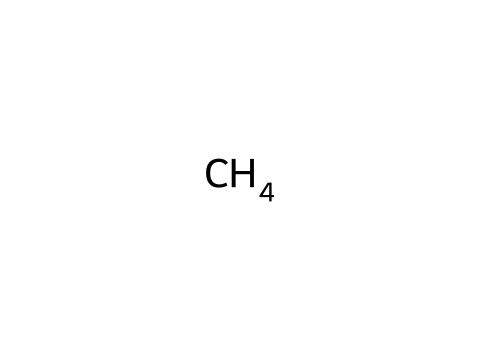

  pose: poses/methane/pose_001.pdbqt | pdb: poses/methane/pose_001.pdb
  pose: poses/methane/pose_002.pdbqt | pdb: poses/methane/pose_002.pdb
benzene 2D: ligands/benzene/ligand_2d.svg


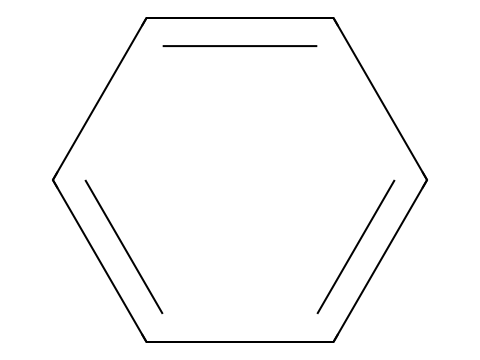

  pose: poses/benzene/pose_001.pdbqt | pdb: poses/benzene/pose_001.pdb
  pose: poses/benzene/pose_002.pdbqt | pdb: poses/benzene/pose_002.pdb
acetic_acid 2D: ligands/acetic_acid/ligand_2d.svg


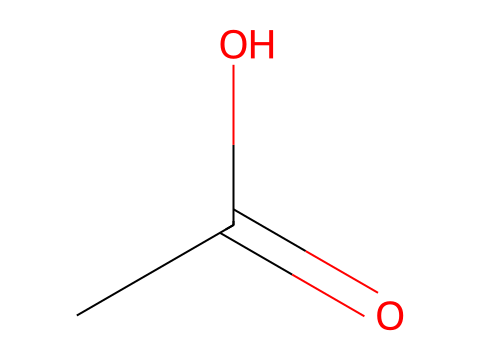

  pose: poses/acetic_acid/pose_001.pdbqt | pdb: poses/acetic_acid/pose_001.pdb
  pose: poses/acetic_acid/pose_002.pdbqt | pdb: poses/acetic_acid/pose_002.pdb


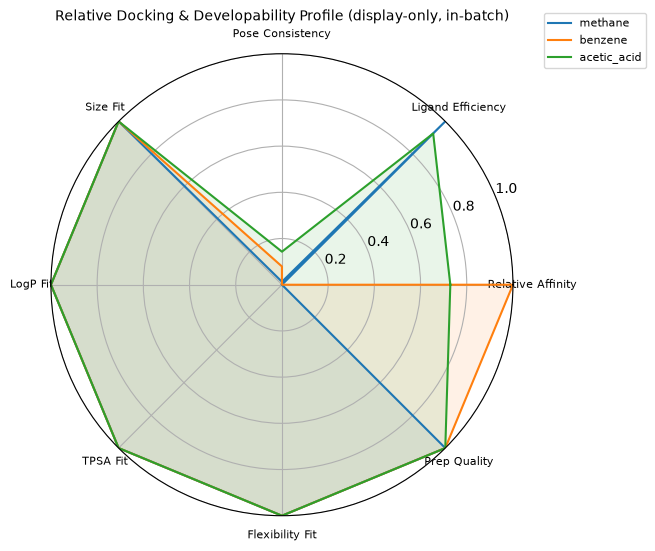

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# 2D 图与 3D pose 文件路径（来自真实任务产物）
for res in outcome.output.results:
    svg_path = job_dir / "ligands" / res.ligand_id / "ligand_2d.svg"
    if svg_path.is_file():
        print(res.ligand_id, "2D:", svg_path.relative_to(job_dir))
        display(SVG(svg_path.read_bytes()))
    for pose in res.poses[:2]:
        print(" ", "pose:", pose.pose_file, "| pdb:", pose.pose_pdb_file)

# 雷达图：统一方向归一化后的展示性指标
dimensions = [
    ("Relative Affinity", "relative_affinity"),
    ("Ligand Efficiency", "ligand_efficiency_rank_norm"),
    ("Pose Consistency", "pose_consistency"),
    ("Size Fit", "molwt_fit"),
    ("LogP Fit", "logp_fit"),
    ("TPSA Fit", "tpsa_fit"),
    ("Flexibility Fit", "flexibility_fit"),
    ("Prep Quality", "preparation_quality"),
]
labels = [label for label, _ in dimensions]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"polar": True})
for res in outcome.output.results:
    entry = comparison.metrics[res.ligand_id]
    values = [float(entry.get(key, 0.0) or 0.0) for _, key in dimensions]
    values += values[:1]
    ax.plot(angles, values, label=res.ligand_id)
    ax.fill(angles, values, alpha=0.1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylim(0, 1)
ax.set_title(
    "Relative Docking & Developability Profile (display-only, in-batch)",
    fontsize=10,
)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1), fontsize=8)
plt.show()

## 12. 结果解释（固定科学措辞）

In [12]:
result_md = (job_dir / "reports" / "result.md").read_text(encoding="utf-8")
# 只展示报告前 40 行，完整报告见 reports/result.md
print("\n".join(result_md.splitlines()[:40]))

# DockingCopilot Skill 对接结果：multiple_ligands_demo

- job_id: `20260805-035906_multiple_ligands_demo`
- 状态：SUCCESS
- 搜索盒：mode=explicit, center=[18.3, 2.3, 21.4] Å, size=[20.0, 20.0, 20.0] Å
- Vina 参数：exhaustiveness=8, num_modes=9, energy_range=3.0 kcal/mol, cpu=4, seed=42

## 分子结果

| ligand | status | best affinity (kcal/mol) | ligand efficiency | poses |
| --- | --- | --- | --- | --- |
| methane | SUCCESS | -0.896 | 0.8960 | 9 |
| benzene | SUCCESS | -4.526 | 0.7543 | 9 |
| acetic_acid | SUCCESS | -3.542 | 0.8855 | 9 |

### methane
- descriptors: MolWt=16.0 g/mol, LogP=0.636, TPSA=0.0 Å², HBD=0, HBA=0, rotatable_bonds=0
- top-2 pose 能量差 0.013 kcal/mol < 0.5：构象不确定性较高，最优 pose 不应被过度解读。

### benzene
- descriptors: MolWt=78.1 g/mol, LogP=1.687, TPSA=0.0 Å², HBD=0, HBA=0, rotatable_bonds=0
- top-2 pose 能量差 0.079 kcal/mol < 0.5：构象不确定性较高，最优 pose 不应被过度解读。

### acetic_acid
- descriptors: MolWt=60.1 g/mol, LogP=0.091, TPSA=37.3 Å², HBD=1, HBA=1, rotatable_bonds=0
- top-2 pose 能量差 0.143 kcal/mol <

## 13. 科学限制

- Vina affinity 是**经验打分函数与构象搜索的结果**，不能直接等同于
  实验结合自由能、Kd、Ki、IC50 或任何药效结论；
- 受体被视为**刚性**，不考虑诱导契合、蛋白柔性与显式溶剂效应；
- 质子化状态采用工具默认策略，pH 依赖效应未显式建模；
- 不同受体、不同 box、不同质子化状态或不同参数之间的分数**不可横向比较**；
- 多个 pose 分数接近时存在**构象不确定性**，最优 pose 不一定代表真实结合模式；
- 本流程输出用于**假设生成与排序**，不替代实验验证。

## 14. manifest（可复现记录）

In [13]:
manifest = json.loads((job_dir / "manifest.json").read_text(encoding="utf-8"))
for key in (
    "job_id", "input_sha256", "receptor_sha256", "vina_version",
    "rdkit_version", "meeko_version", "python_version", "macos_version",
    "architecture", "random_seed", "status", "runtime_seconds",
):
    print(f"{key}: {manifest.get(key)}")
print("parameters:", json.dumps(manifest["parameters"]))
print("commands_or_api_calls:")
for call in manifest["commands_or_api_calls"]:
    print(" -", call)
print(f"artifact_sha256: {len(manifest['artifact_sha256'])} files hashed")

job_id: 20260805-035906_multiple_ligands_demo
input_sha256: a01da52fe5f6666e18b6c5fc6263de4ca3116c3a482f046d97a7d0745b6f0c89
receptor_sha256: 200f137801aebdfeeb49f25895a234eb2913c62d05d84665d96743823dd643bc
vina_version: AutoDock Vina v1.2.7
rdkit_version: 2025.09.5
meeko_version: 0.7.1
python_version: 3.11.15
macos_version: 26.5.2
architecture: arm64
random_seed: 42
status: SUCCESS
runtime_seconds: 10.955
parameters: {"scoring_function": "vina", "exhaustiveness": 8, "num_modes": 9, "energy_range": 3.0, "cpu": 4, "seed": 42}
commands_or_api_calls:
 - receptor pdbqt via meeko cli (mk_prepare_receptor.py)
 - vina adapters: python_api=True, cli=True
 - dock methane via vina python api (seed=42)
 - dock benzene via vina python api (seed=42)
 - dock acetic_acid via vina python api (seed=42)
artifact_sha256: 15 files hashed


## 15. 产物列表

In [14]:
files = sorted(p.relative_to(job_dir) for p in job_dir.rglob("*") if p.is_file())
print(f"job dir: outputs/{job_dir.name}/")
print(f"{len(files)} files:")
for rel in files:
    print(" ", rel)

job dir: outputs/20260805-035906_multiple_ligands_demo/
84 files:
  bundle.zip
  input.json
  job.json
  ligands/acetic_acid/ligand.pdb
  ligands/acetic_acid/ligand.pdbqt
  ligands/acetic_acid/ligand.sdf
  ligands/acetic_acid/ligand_2d.svg
  ligands/acetic_acid/ligand_metadata.json
  ligands/acetic_acid/vina_output.pdbqt
  ligands/benzene/ligand.pdb
  ligands/benzene/ligand.pdbqt
  ligands/benzene/ligand.sdf
  ligands/benzene/ligand_2d.svg
  ligands/benzene/ligand_metadata.json
  ligands/benzene/vina_output.pdbqt
  ligands/methane/ligand.pdb
  ligands/methane/ligand.pdbqt
  ligands/methane/ligand.sdf
  ligands/methane/ligand_2d.svg
  ligands/methane/ligand_metadata.json
  ligands/methane/vina_output.pdbqt
  logs/workflow.log
  manifest.json
  poses/acetic_acid/pose_001.pdb
  poses/acetic_acid/pose_001.pdbqt
  poses/acetic_acid/pose_002.pdb
  poses/acetic_acid/pose_002.pdbqt
  poses/acetic_acid/pose_003.pdb
  poses/acetic_acid/pose_003.pdbqt
  poses/acetic_acid/pose_004.pdb
  poses/acet